# 04 — Additional Baselines, Class Imbalance & Tuning (Package B — Dulsara)
EC5203 Group 07 — Multi-Class Chronic Disease Prediction

Package B tasks (revised work allocation):
1. Decision Tree and SVM baselines (`src/models_baseline_b.py`, first results in `03b_feature_selection_baseline_b.ipynb`)
2. **Bounded hyperparameter tuning with cross-validation** on training data → `dulsara_cv_tuning.csv`
3. **Class-weighted vs unweighted**, plus training-only **random oversampling** and **SMOTE** → `dulsara_imbalance_comparison.csv`
4. Per-class confusion patterns, runtime, seeds, chosen hyperparameters, limitations

Common protocol: `prepare_dataset()` → `split_three_ways()` (70/15/15, seed 42) → `build_pipeline()` (engineered features).
Primary metric: **macro F1**. Resampling sits inside an imbalanced-learn Pipeline, so it only touches training data / CV training folds.
**The test set is not used.**

In [ ]:
from pathlib import Path
import sys, json, platform, time

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "src").is_dir():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Project src folder was not found.")
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, imblearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import ConfusionMatrixDisplay

from src.preprocessing import prepare_dataset
from src.three_way_split import split_three_ways
from src.imbalance_experiments import (build_imbalance_pipeline, tune_with_cv,
                                       evaluate_on_validation, STRATEGIES, RARE_CLASSES)

RANDOM_STATE = 42
USE_ENGINEERING = True       # engineered features gave the best validation results so far
SVM_TRAIN_LIMIT = 10_000     # RBF SVM is O(n^2) in training rows; documented simplification
CV_FOLDS = 3                 # bounded tuning budget

TAB_DIR = PROJECT_ROOT / "results" / "tables";  TAB_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
print("sklearn", sklearn.__version__, "| imblearn", imblearn.__version__, "| python", platform.python_version())

## 1. Data and the approved 70/15/15 split

In [ ]:
X, y = prepare_dataset(PROJECT_ROOT / "data" / "raw" / "Data Warehouse Multiclass.csv")
X_train, X_val, X_test, y_train, y_val, y_test = split_three_ways(X, y, random_state=RANDOM_STATE)
del X_test, y_test   # reserved for the final coordinated evaluation (Esandu)

groups_train = pd.util.hash_pandas_object(X_train, index=False)

# Select one group-aware fold close to 10k rows for the RBF SVM.
SVM_SUBSET_FOLDS = max(2, round(len(X_train) / SVM_TRAIN_LIMIT))
subset_cv = StratifiedGroupKFold(
    n_splits=SVM_SUBSET_FOLDS, shuffle=True, random_state=RANDOM_STATE
)
_, svm_subset_idx = next(subset_cv.split(X_train, y_train, groups_train))
X_svm = X_train.iloc[svm_subset_idx].copy()
y_svm = y_train.iloc[svm_subset_idx].copy()
groups_svm = groups_train.iloc[svm_subset_idx].copy()

expected_classes = set(y_train.unique())
svm_classes = set(y_svm.unique())
print("SVM subset rows:", len(X_svm), "| classes:", sorted(svm_classes))
assert len(expected_classes) == 8 and svm_classes == expected_classes, (
    f"SVM subset must contain all eight training classes; got {sorted(svm_classes)}"
)
print("Decision Tree training rows:", len(X_train), "| SVM training rows:", len(X_svm), "| validation:", len(X_val))

## 2. Bounded CV tuning — Decision Tree (full training set, class-weighted)
Grid: `max_depth` ∈ {8, 12, 16, 20} × `min_samples_leaf` ∈ {1, 20, 50} — 12 settings × 3 folds.

In [ ]:
dt_grid = {"classifier__max_depth": [8, 12, 16, 20],
           "classifier__min_samples_leaf": [1, 20, 50]}
dt_search, dt_cv, dt_seconds = tune_with_cv(
    build_imbalance_pipeline(
        "decision_tree", X_train, "class_weight", USE_ENGINEERING
    ),
    dt_grid,
    X_train,
    y_train,
    groups_train,
    n_splits=CV_FOLDS,
    random_state=RANDOM_STATE,
    n_jobs=1
)

DT_BEST = {k.replace("classifier__", ""): v for k, v in dt_search.best_params_.items()}
print(f"Decision Tree tuning: {dt_seconds:.0f}s | best {DT_BEST} | CV macro F1 = {dt_search.best_score_:.4f}")
dt_cv.head(12)

## 3. Bounded CV tuning — SVM (RBF, 10k stratified training subset, class-weighted)
Grid: `C` ∈ {0.3, 1, 3, 10} × `gamma` ∈ {"scale", 0.01, 0.1} — 12 settings × 3 folds.

In [ ]:
svm_grid = {"classifier__C": [0.3, 1, 3, 10],
            "classifier__gamma": ["scale", 0.01, 0.1]}
svm_search, svm_cv, svm_seconds = tune_with_cv(
    build_imbalance_pipeline("svm", X_svm, "class_weight", USE_ENGINEERING),
    svm_grid, X_svm, y_svm, groups_svm, n_splits=CV_FOLDS, random_state=RANDOM_STATE)

SVM_BEST = {k.replace("classifier__", ""): v for k, v in svm_search.best_params_.items()}
print(f"SVM tuning: {svm_seconds:.0f}s | best {SVM_BEST} | CV macro F1 = {svm_search.best_score_:.4f}")
svm_cv.head(12)

In [5]:
dt_cv.insert(0, "Model", "Decision Tree"); svm_cv.insert(0, "Model", "SVM (RBF)")
cv_tuning = pd.concat([dt_cv, svm_cv], ignore_index=True)
cv_tuning.to_csv(TAB_DIR / "dulsara_cv_tuning.csv", index=False)
print("Saved dulsara_cv_tuning.csv:", cv_tuning.shape)

Saved dulsara_cv_tuning.csv: (24, 11)


## 4. Class-imbalance comparison on the validation set (tuned hyperparameters)
Strategies: `unweighted`, `class_weight="balanced"`, `random_oversample` (training only), `smote` (training only).

In [6]:
rows, reports, preds = [], [], {}
for strategy in STRATEGIES:
    for model_key, name, Xtr, ytr, params in [
        ("decision_tree", "Decision Tree", X_train, y_train, DT_BEST),
        ("svm", "SVM (RBF)", X_svm, y_svm, SVM_BEST),
    ]:
        pipe = build_imbalance_pipeline(model_key, Xtr, strategy, USE_ENGINEERING, params)
        row, rep, pred = evaluate_on_validation(pipe, Xtr, ytr, X_val, y_val, name, strategy)
        rows.append(row); reports.append(rep); preds[(name, strategy)] = pred
        print(f"{name:14s} {strategy:18s} macroF1={row['Macro_F1']:.4f} "
              f"balAcc={row['Balanced_Accuracy']:.4f} rareRecall={row['Rare_Class_Mean_Recall']:.4f} ({row['Fit_Seconds']}s)")

imbalance = pd.DataFrame(rows).sort_values(["Model", "Macro_F1"], ascending=[True, False]).reset_index(drop=True)
imbalance.to_csv(TAB_DIR / "dulsara_imbalance_comparison.csv", index=False)
pd.concat(reports).to_csv(TAB_DIR / "dulsara_class_wise_validation_metrics.csv")
imbalance

Decision Tree  unweighted         macroF1=0.3594 balAcc=0.3646 rareRecall=0.0406 (5.5s)


SVM (RBF)      unweighted         macroF1=0.3295 balAcc=0.3393 rareRecall=0.0012 (5.2s)


Decision Tree  class_weight       macroF1=0.3708 balAcc=0.4824 rareRecall=0.3578 (5.0s)


SVM (RBF)      class_weight       macroF1=0.3636 balAcc=0.4406 rareRecall=0.2664 (5.7s)


Decision Tree  random_oversample  macroF1=0.3767 balAcc=0.4976 rareRecall=0.3806 (12.0s)


SVM (RBF)      random_oversample  macroF1=0.3592 balAcc=0.4383 rareRecall=0.2697 (15.4s)


Decision Tree  smote              macroF1=0.3768 balAcc=0.4961 rareRecall=0.3798 (28.1s)


SVM (RBF)      smote              macroF1=0.3686 balAcc=0.4398 rareRecall=0.2574 (15.4s)


,Model,Strategy,Training_Rows,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy,Rare_Class_Mean_Recall,Fit_Seconds,Recall_HT,Recall_HT_HY,Recall_DI_HT,Recall_DI_HT_HY
0,Decision Tree,smote,195091,0.654635,0.376781,0.674917,0.496120,0.379760,28.1,0.487113,0.30625,0.392344,0.333333
1,Decision Tree,random_oversample,195091,0.656022,0.376723,0.676191,0.497606,0.380643,12.0,0.432990,0.36250,0.354067,0.373016
2,Decision Tree,class_weight,195091,0.637531,0.370756,0.665372,0.482397,0.357843,5.0,0.525773,0.25625,0.363636,0.285714
3,Decision Tree,unweighted,195091,0.751226,0.359368,0.725256,0.364603,0.040556,5.5,0.038660,0.03125,0.052632,0.039683
4,SVM (RBF),smote,10000,0.656142,0.368578,0.674523,0.439828,0.257447,15.4,0.438144,0.13125,0.349282,0.111111
5,SVM (RBF),class_weight,10000,0.642722,0.363650,0.665689,0.440601,0.266450,5.7,0.466495,0.15000,0.354067,0.095238
6,SVM (RBF),random_oversample,10000,0.631121,0.359230,0.657202,0.438256,0.269672,15.4,0.479381,0.15000,0.354067,0.095238
7,SVM (RBF),unweighted,10000,0.737783,0.329470,0.713106,0.339346,0.001196,5.2,0.000000,0.00000,0.004785,0.000000


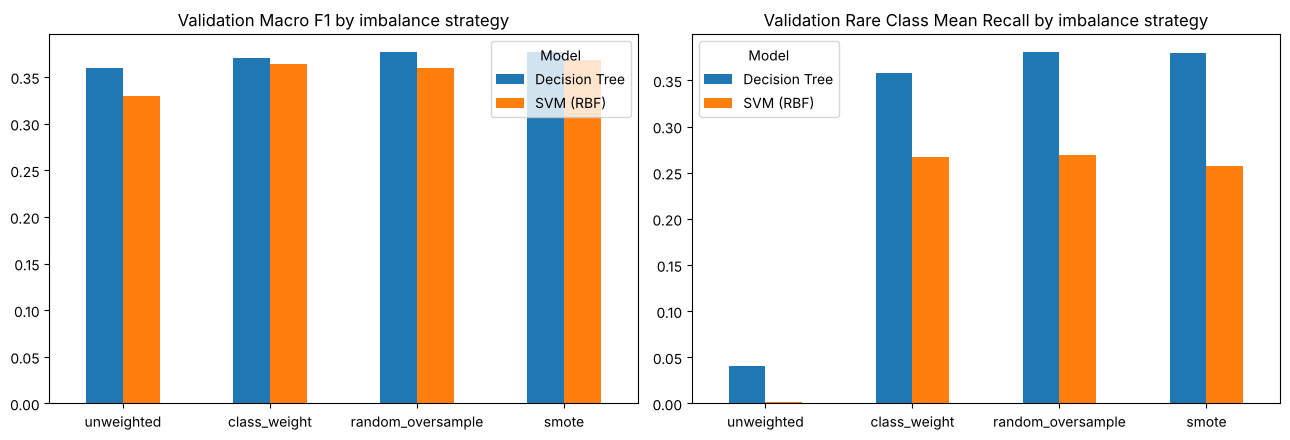

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["Macro_F1", "Rare_Class_Mean_Recall"]):
    imbalance.pivot(index="Strategy", columns="Model", values=metric).loc[STRATEGIES].plot.bar(ax=ax, rot=0)
    ax.set_title(f"Validation {metric.replace('_', ' ')} by imbalance strategy"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_dulsara_imbalance_comparison.png", dpi=150); plt.show()

## 5. Per-class confusion patterns — best strategy per model family (row-normalised)

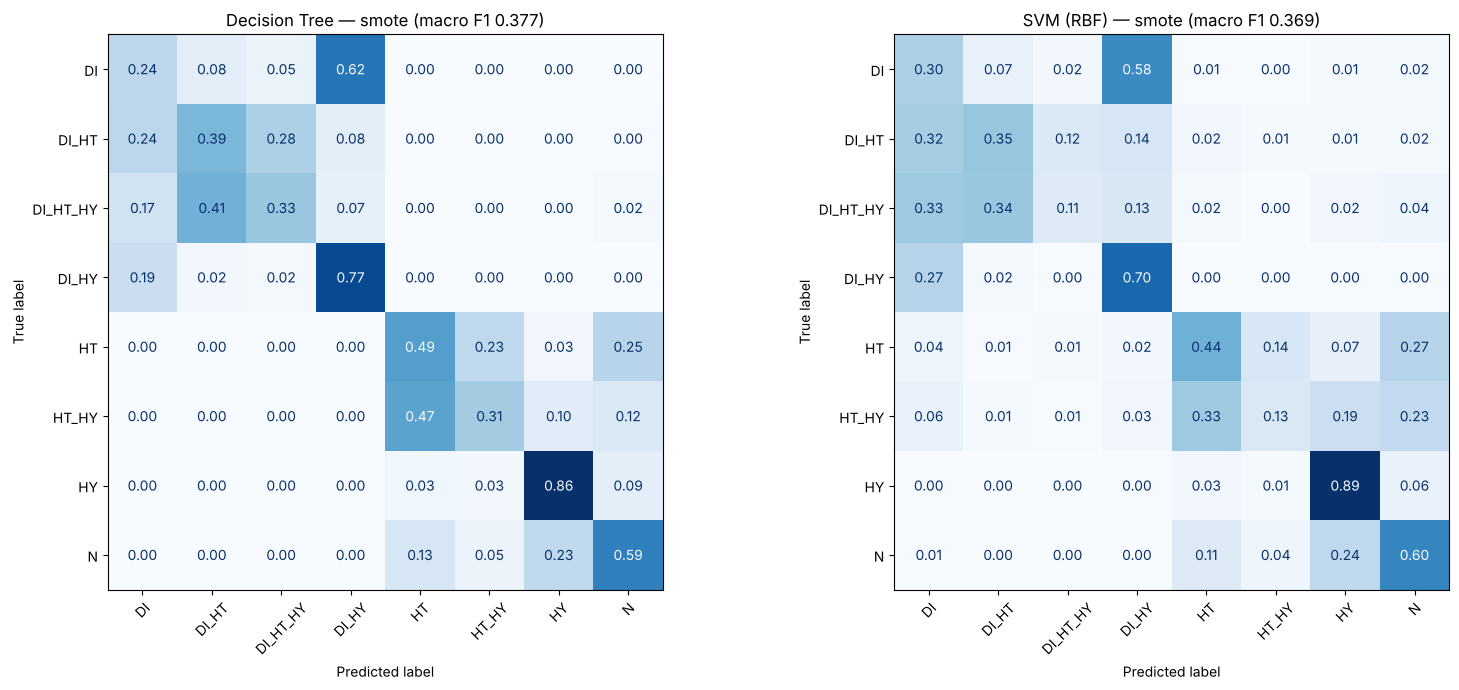

,Model,Strategy,Training_Rows,Accuracy,Macro_F1,Weighted_F1,Balanced_Accuracy,Rare_Class_Mean_Recall,Fit_Seconds,Recall_HT,Recall_HT_HY,Recall_DI_HT,Recall_DI_HT_HY
0,Decision Tree,smote,195091,0.654635,0.376781,0.674917,0.496120,0.379760,28.1,0.487113,0.30625,0.392344,0.333333
4,SVM (RBF),smote,10000,0.656142,0.368578,0.674523,0.439828,0.257447,15.4,0.438144,0.13125,0.349282,0.111111


In [8]:
best_per_model = imbalance.loc[imbalance.groupby("Model")["Macro_F1"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (_, r) in zip(axes, best_per_model.iterrows()):
    ConfusionMatrixDisplay.from_predictions(y_val, preds[(r["Model"], r["Strategy"])], ax=ax,
                                            normalize="true", values_format=".2f",
                                            xticks_rotation=45, cmap="Blues", colorbar=False)
    ax.set_title(f"{r['Model']} — {r['Strategy']} (macro F1 {r['Macro_F1']:.3f})")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_dulsara_confusion_matrices.png", dpi=150); plt.show()
best_per_model

## 6. Settings, runtime and chosen hyperparameters (reproducibility)

In [9]:
settings = {
    "random_state": RANDOM_STATE, "split": "70/15/15 grouped (src.three_way_split)",
    "use_engineering": USE_ENGINEERING, "cv_folds": CV_FOLDS, "svm_train_limit": SVM_TRAIN_LIMIT,
    "decision_tree": {"grid": dt_grid, "best": DT_BEST, "cv_macro_f1": dt_search.best_score_,
                      "tuning_seconds": round(dt_seconds, 1)},
    "svm_rbf": {"grid": svm_grid, "best": SVM_BEST, "cv_macro_f1": svm_search.best_score_,
                "tuning_seconds": round(svm_seconds, 1)},
    "best_validation": best_per_model[["Model", "Strategy", "Macro_F1", "Balanced_Accuracy"]].to_dict("records"),
    "test_set_used": False,
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                 "imblearn": imblearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
with open(TAB_DIR / "dulsara_settings.json", "w") as f:
    json.dump(settings, f, indent=2, default=str)
settings

{'random_state': 42,
 'split': '70/15/15 grouped (src.three_way_split)',
 'use_engineering': True,
 'cv_folds': 3,
 'svm_train_limit': 10000,
 'decision_tree': {'grid': {'classifier__max_depth': [8, 12, 16, 20],
   'classifier__min_samples_leaf': [1, 20, 50]},
  'best': {'max_depth': 16, 'min_samples_leaf': 1},
  'cv_macro_f1': np.float64(0.37549537684693096),
  'tuning_seconds': 43.1},
 'svm_rbf': {'grid': {'classifier__C': [0.3, 1, 3, 10],
   'classifier__gamma': ['scale', 0.01, 0.1]},
  'best': {'C': 3, 'gamma': 'scale'},
  'cv_macro_f1': np.float64(0.35099526717554647),
  'tuning_seconds': 47.3},
 'best_validation': [{'Model': 'Decision Tree',
   'Strategy': 'smote',
   'Macro_F1': 0.37678080169243144,
   'Balanced_Accuracy': 0.49611959700501507},
  {'Model': 'SVM (RBF)',
   'Strategy': 'smote',
   'Macro_F1': 0.36857782363908154,
   'Balanced_Accuracy': 0.4398283225520514}],
 'test_set_used': False,
 'versions': {'python': '3.13.18',
  'sklearn': '1.9.1',
  'imblearn': '0.14.2',
 

## 7. Interpretation and limitations
See `results/tables/dulsara_package_b_handoff.md` for the written summary of tuning, imbalance and class-wise findings.

Limitations: RBF SVM trained on a 10k stratified subset; bounded 3-fold grids; tuning was done with class weighting and the
tuned settings were reused for the other strategies; rare classes remain hard; clinical units unverified.